In [55]:
!pip install xgboost lightgbm catboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

In [56]:
df = pd.read_csv('/content/Ames Housing Dataset.csv')
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [58]:
df.select_dtypes('number').columns

Index(['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd',
       'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF',
       'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',
       'MiscVal', 'MoSold', 'YrSold', 'SalePrice'],
      dtype='object')

In [59]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [60]:
df.isnull().sum()

,0
Id,0
MSSubClass,0
MSZoning,0
LotFrontage,259
LotArea,0
...,...
MoSold,0
YrSold,0
SaleType,0
SaleCondition,0


In [61]:
df.isnull().sum().sum()

np.int64(7829)

In [62]:
df.duplicated().sum()

np.int64(0)

In [63]:
dropcols = ['PoolQC','MiscFeature','Alley','Fence','Id']
df_clean = df.drop(columns= dropcols, inplace=True)

In [64]:
df.shape

(1460, 76)

In [65]:
nullcols=['FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
          'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType']

In [66]:
for col in nullcols:
  df[col] = df[col].fillna('None')
df['MasVnrArea'] = df['MasVnrArea'].fillna(0)
df['GarageYrBlt'] = df['GarageYrBlt'].fillna('None')
df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])

from sklearn.impute import KNNImputer
knn_features = ['LotFrontage', 'LotArea', '1stFlrSF', 'GrLivArea']
imputer = KNNImputer(n_neighbors=5)
df[knn_features] = imputer.fit_transform(df[knn_features])

In [67]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 76 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1460 non-null   int64  
 1   MSZoning       1460 non-null   object 
 2   LotFrontage    1460 non-null   float64
 3   LotArea        1460 non-null   float64
 4   Street         1460 non-null   object 
 5   LotShape       1460 non-null   object 
 6   LandContour    1460 non-null   object 
 7   Utilities      1460 non-null   object 
 8   LotConfig      1460 non-null   object 
 9   LandSlope      1460 non-null   object 
 10  Neighborhood   1460 non-null   object 
 11  Condition1     1460 non-null   object 
 12  Condition2     1460 non-null   object 
 13  BldgType       1460 non-null   object 
 14  HouseStyle     1460 non-null   object 
 15  OverallQual    1460 non-null   int64  
 16  OverallCond    1460 non-null   int64  
 17  YearBuilt      1460 non-null   int64  
 18  YearRemo

In [68]:
df.isnull().sum().sum()

np.int64(0)

In [69]:
for i in df.select_dtypes('object').columns:
    print(f"Unique values in '{i}':", df[i].nunique())
    print('*' * 50)

Unique values in 'MSZoning': 5
**************************************************
Unique values in 'Street': 2
**************************************************
Unique values in 'LotShape': 4
**************************************************
Unique values in 'LandContour': 4
**************************************************
Unique values in 'Utilities': 2
**************************************************
Unique values in 'LotConfig': 5
**************************************************
Unique values in 'LandSlope': 3
**************************************************
Unique values in 'Neighborhood': 25
**************************************************
Unique values in 'Condition1': 9
**************************************************
Unique values in 'Condition2': 8
**************************************************
Unique values in 'BldgType': 5
**************************************************
Unique values in 'HouseStyle': 8
**************************************************
U

In [70]:
df.select_dtypes('object').columns

Index(['MSZoning', 'Street', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation',
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual',
       'Functional', 'FireplaceQu', 'GarageType', 'GarageYrBlt',
       'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'SaleType',
       'SaleCondition'],
      dtype='object')

In [71]:
ocols=['MSZoning', 'Street', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation',
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual',
       'Functional', 'FireplaceQu', 'GarageType','GarageFinish', 'GarageQual',
       'GarageCond', 'PavedDrive', 'SaleType','SaleCondition']

from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(handle_unknown='ignore')
for i in ocols :
  ohe_encoded = ohe.fit_transform(df[[i]]).toarray()
  ohe_df = pd.DataFrame(ohe_encoded,columns = ohe.get_feature_names_out([i]),index=df.index)
  df = pd.concat([df,ohe_df],axis=1)
  df.drop(i , axis=1,inplace=True)

In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Columns: 286 entries, MSSubClass to SaleCondition_Partial
dtypes: float64(254), int64(31), object(1)
memory usage: 3.2+ MB


In [73]:
for i in df.select_dtypes('object').columns:
    print(f"Unique values in '{i}':", df[i].nunique())
    print('*' * 50)

Unique values in 'GarageYrBlt': 98
**************************************************


In [74]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for i in df.select_dtypes('object').columns:
  df[i] = df[i].astype(str)
  df[i] = le.fit_transform(df[i])

In [75]:
x = df.drop('SalePrice', axis=1)
y = df['SalePrice']

In [76]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=100 , stratify=None)

In [77]:
numcols =['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd',
       'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF',
       'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',
       'MiscVal', 'MoSold', 'YrSold']



In [78]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train[numcols] = sc.fit_transform(x_train[numcols])
x_test[numcols] = sc.transform(x_test[numcols])

# **LinearRegression**

In [79]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

results = []

model = LinearRegression()
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

results.append({
    'Method' : 'LinearRegression',
    'R2 Score' : r2_score(y_test, y_pred),
    'MAE' : mean_absolute_error(y_test, y_pred)
})
res=pd.DataFrame(results)
res

,Method,R2 Score,MAE
0,LinearRegression,0.805131,18663.322662


# **KNN**

In [80]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_absolute_error

model = KNeighborsRegressor(n_neighbors=3, metric='minkowski', p=1)
model.fit(x_train, y_train)

y_pred_test = model.predict(x_test)


results.append({
    'Method' : 'KNN',
    'R2 Score' : r2_score(y_test, y_pred_test),
    'MAE' : mean_absolute_error(y_test, y_pred_test)
})
res=pd.DataFrame(results)
res

,Method,R2 Score,MAE
0,LinearRegression,0.805131,18663.322662
1,KNN,0.827544,21180.428082


# **Naive Bayes**

In [81]:
from sklearn.naive_bayes import GaussianNB

model.fit(x_train, y_train)

y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)

results.append({
    'Method' : 'Naive Bayes',
    'R2 Score' : r2_score(y_test, y_pred_test),
    'MAE' : mean_absolute_error(y_test, y_pred_test)
})


In [82]:
res=pd.DataFrame(results)
res

,Method,R2 Score,MAE
0,LinearRegression,0.805131,18663.322662
1,KNN,0.827544,21180.428082
2,Naive Bayes,0.827544,21180.428082


# **Support Vector Machine**

In [83]:
from sklearn.svm import SVR

model = SVR(C=0.1, kernel='rbf', gamma=1.0)
model.fit(x_train, y_train)

SVR(C=0.1, gamma=1.0)

In [84]:
y_pred = model.predict(x_test)

In [85]:
results.append({
    'Method' : 'SVR',
    'R2 Score' : r2_score(y_test, y_pred_test),
    'MAE' : mean_absolute_error(y_test, y_pred_test)
})

In [86]:
res = pd.DataFrame(results)
res

,Method,R2 Score,MAE
0,LinearRegression,0.805131,18663.322662
1,KNN,0.827544,21180.428082
2,Naive Bayes,0.827544,21180.428082
3,SVR,0.827544,21180.428082


## **Decision** **Tree**

In [87]:
from sklearn.tree import DecisionTreeRegressor,plot_tree


In [88]:
model = DecisionTreeRegressor(criterion='squared_error',
                              random_state=100,
                              max_depth=5,
                              min_samples_split=10,
                              min_samples_leaf=5,
                              min_impurity_decrease=0.01,
                              ccp_alpha=0.01
)

In [89]:
model.fit(x_train, y_train)

y_pred_train = model.predict(x_train)
y_pred_test  = model.predict(x_test)

results.append({
    'Method' : 'DecisionTreeRegressor',
    'R2 Score' : r2_score(y_test, y_pred_test),
    'MAE' : mean_absolute_error(y_test, y_pred_test)
})

In [90]:
res = pd.DataFrame(results)
res

,Method,R2 Score,MAE
0,LinearRegression,0.805131,18663.322662
1,KNN,0.827544,21180.428082
2,Naive Bayes,0.827544,21180.428082
3,SVR,0.827544,21180.428082
4,DecisionTreeRegressor,0.790244,25192.469268


Decision Tree - Plotting the tree


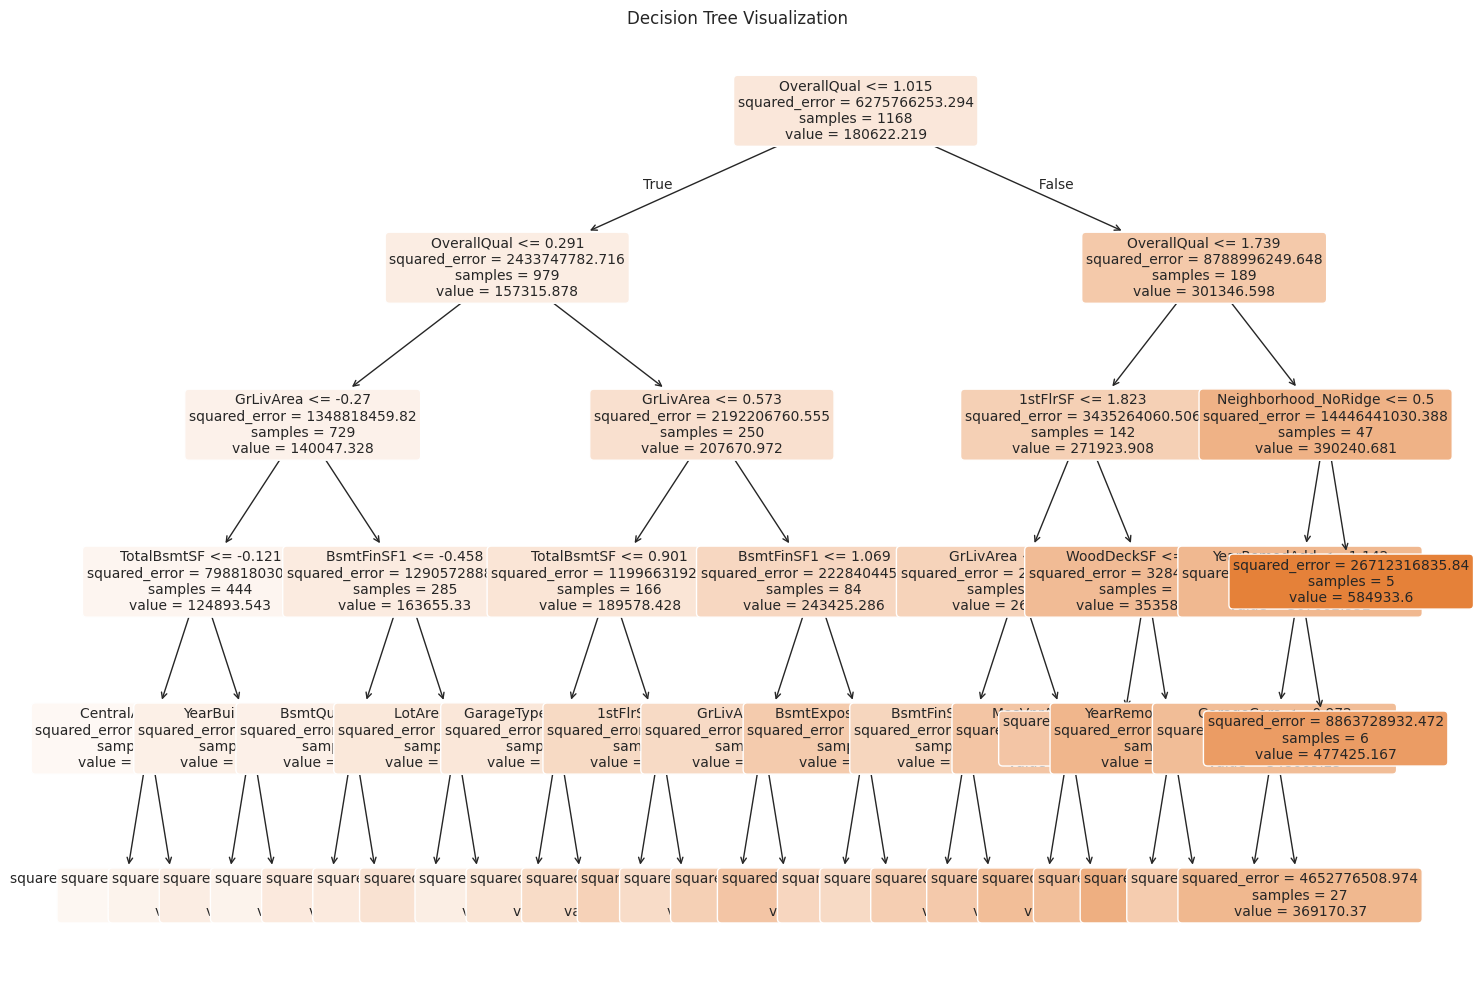

In [91]:
print("Decision Tree - Plotting the tree")

plt.figure(figsize=(15, 10))
plot_tree(
    model,
    feature_names=x.columns.tolist(),
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Visualization")
plt.tight_layout()
plt.show()

In [92]:
rf = DecisionTreeRegressor( random_state=42)
rf.fit(x_train, y_train)

# Get top 10 important features
importances = pd.Series(rf.feature_importances_,index=x.columns)

importances = importances.sort_values(ascending=False)

selected_columns = importances.sort_values(ascending=False).index[:5]
print("Random Forest Selected Features:",selected_columns.tolist())
selected_features = importances.nlargest(5)
print("Random Forest Selected Features:", selected_features.tolist())

Random Forest Selected Features: ['OverallQual', 'GrLivArea', '2ndFlrSF', 'BsmtFinSF1', 'TotalBsmtSF']
Random Forest Selected Features: [0.608594606225071, 0.08607432782641948, 0.06978885366118429, 0.03151223053747276, 0.028242837205802396]


In [93]:
# from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score, StratifiedKFold
# grid_params = {
#   'n_neighbors': [3, 5, 7, 9, 11, 15],
#     'weights': ['uniform', 'distance'],
#     'p': [1, 2]
# }

In [94]:
# grid = GridSearchCV(estimator=KNeighborsRegressor(), param_grid=grid_params, cv=5, scoring='accuracy')

# grid.fit(x_train, y_train)

In [95]:
# print(grid.best_params_)
# print(grid.best_score_)

In [96]:
sns.set_theme(style="whitegrid")

/tmp/ipykernel_1393/2777573024.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette="Blues_r")


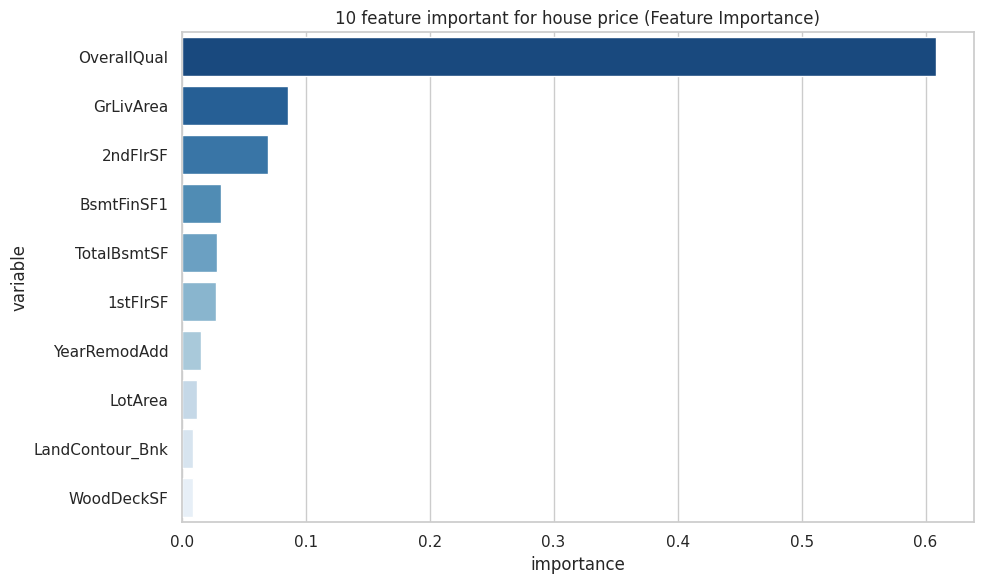

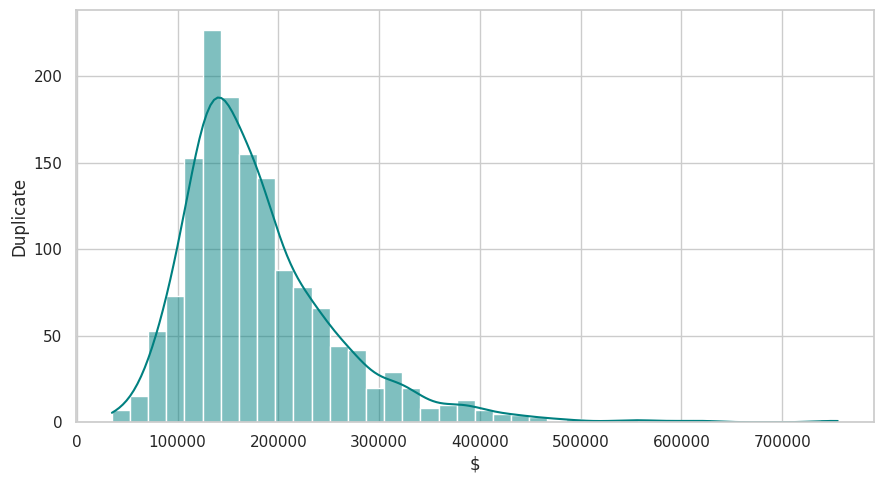

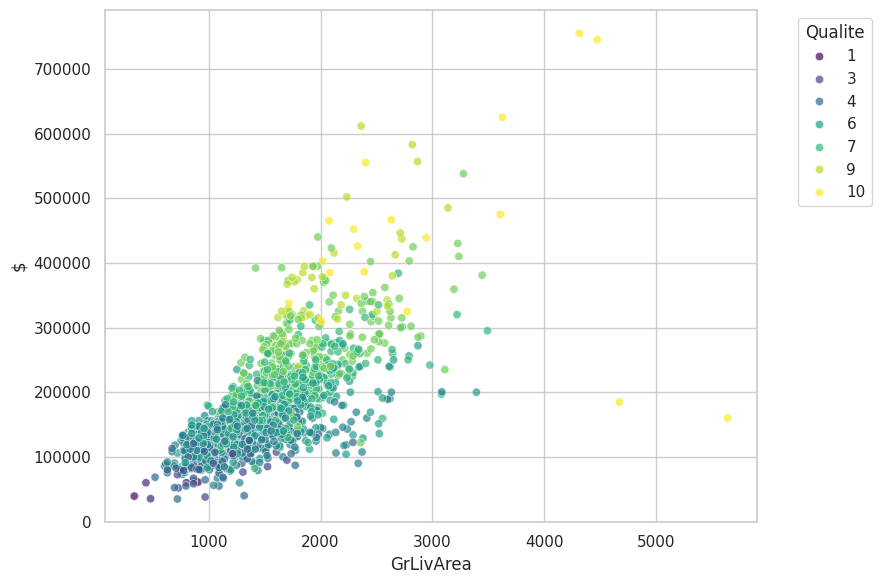

In [97]:
plt.figure(figsize=(10, 6))
importances = pd.Series(rf.feature_importances_, index=x.columns).sort_values(ascending=False).head(10)
sns.barplot(x=importances.values, y=importances.index, palette="Blues_r")
plt.title("10 feature important for house price (Feature Importance)")
plt.xlabel("importance")
plt.ylabel("variable")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.histplot(df['SalePrice'], kde=True, color='teal', bins=40)
plt.xlabel('$')
plt.ylabel('Duplicate')
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x='GrLivArea',
    y='SalePrice',
    hue='OverallQual',
    palette='viridis',
    alpha=0.7,
)

plt.xlabel('GrLivArea')
plt.ylabel('$')
plt.legend(title='Qualite', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [98]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [99]:
# Metrics function
def regression_metrics(model, x, y_actual):
    y_pred = model.predict(x)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

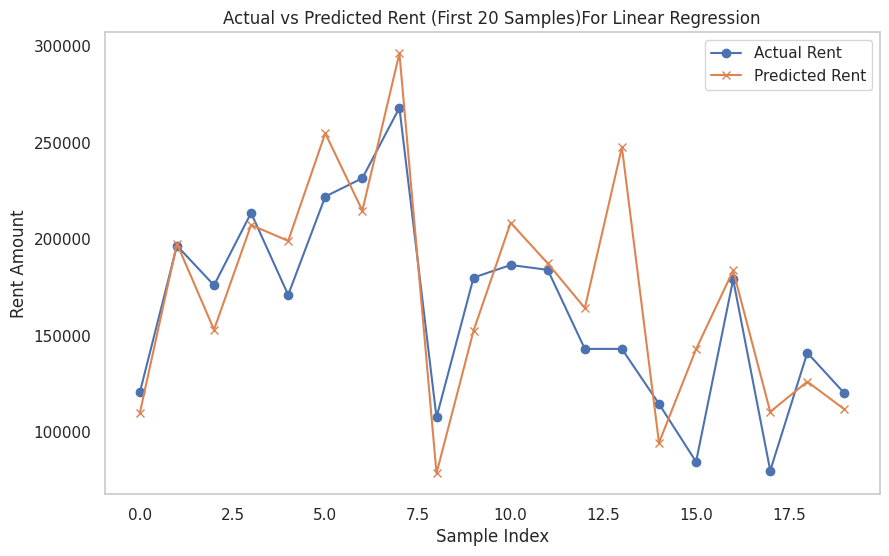

  7%|▋         | 1/15 [00:00<00:06,  2.10it/s]

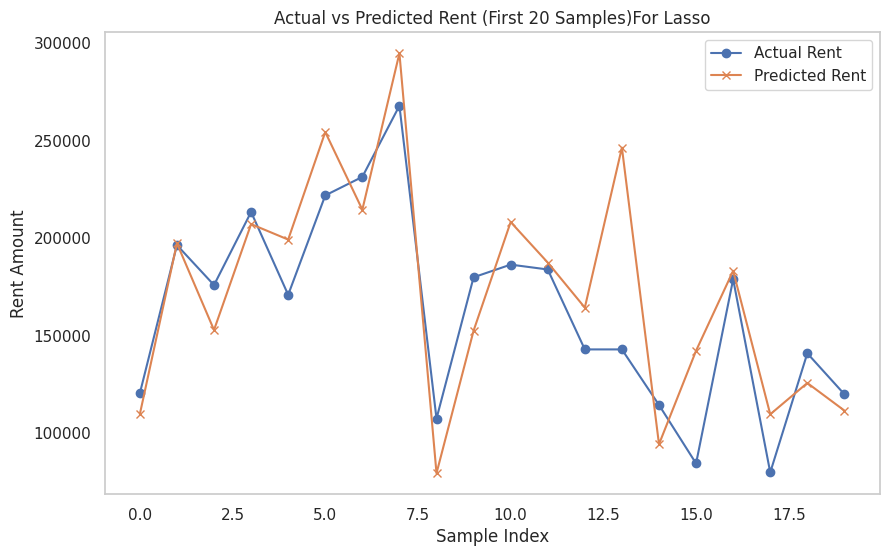

 13%|█▎        | 2/15 [00:01<00:07,  1.72it/s]

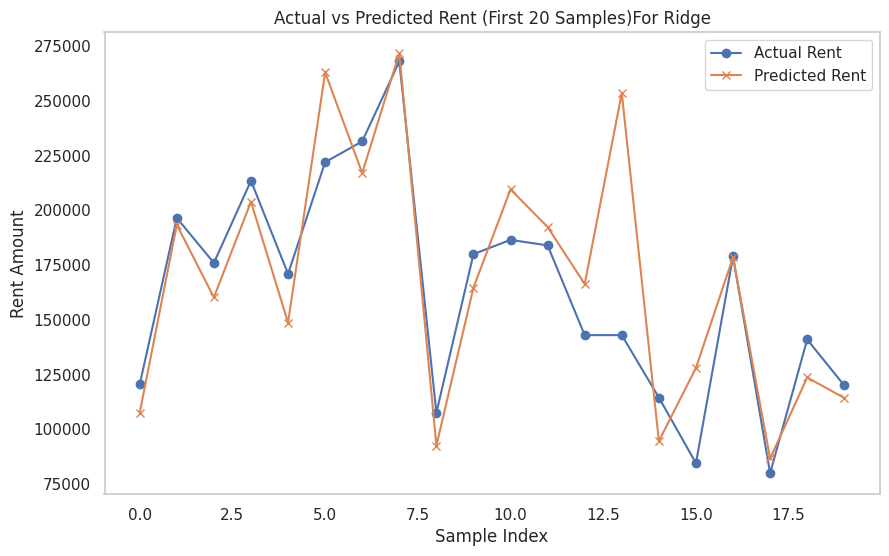

 20%|██        | 3/15 [00:01<00:06,  1.86it/s]

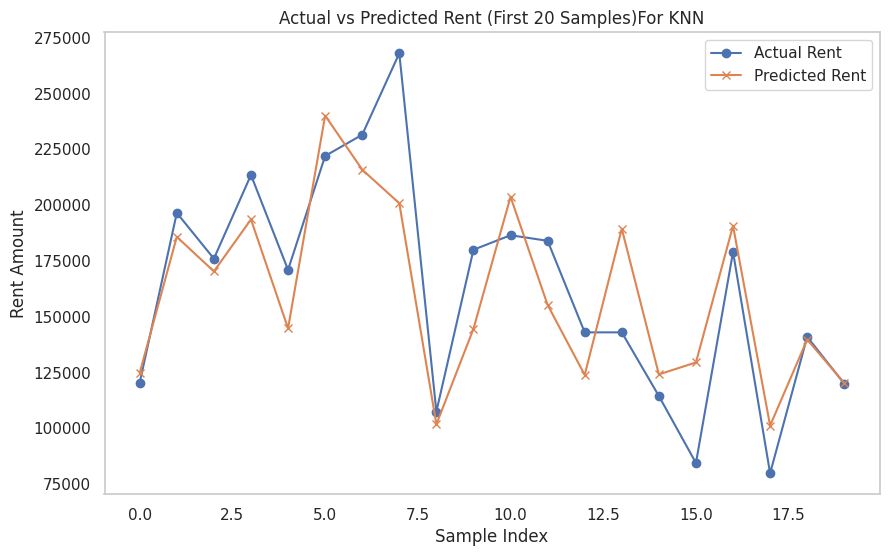

 27%|██▋       | 4/15 [00:04<00:16,  1.47s/it]

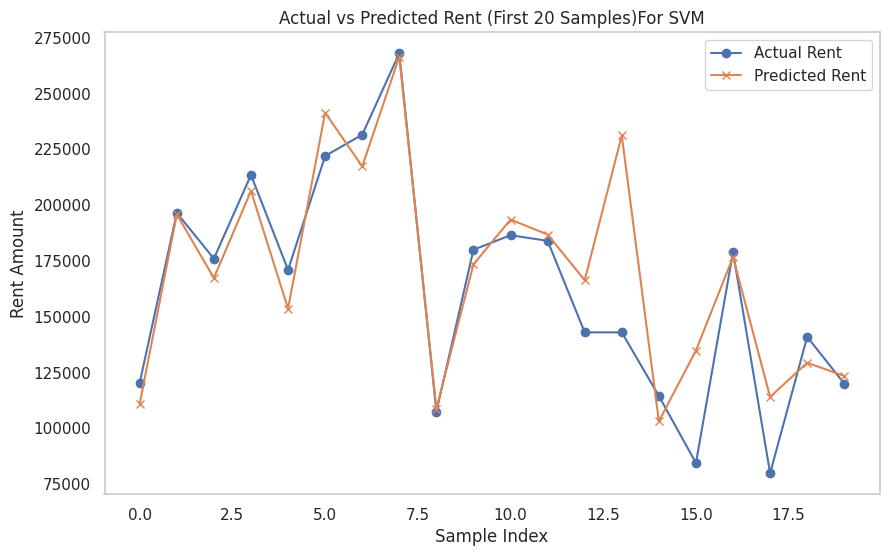

 33%|███▎      | 5/15 [00:06<00:16,  1.65s/it]

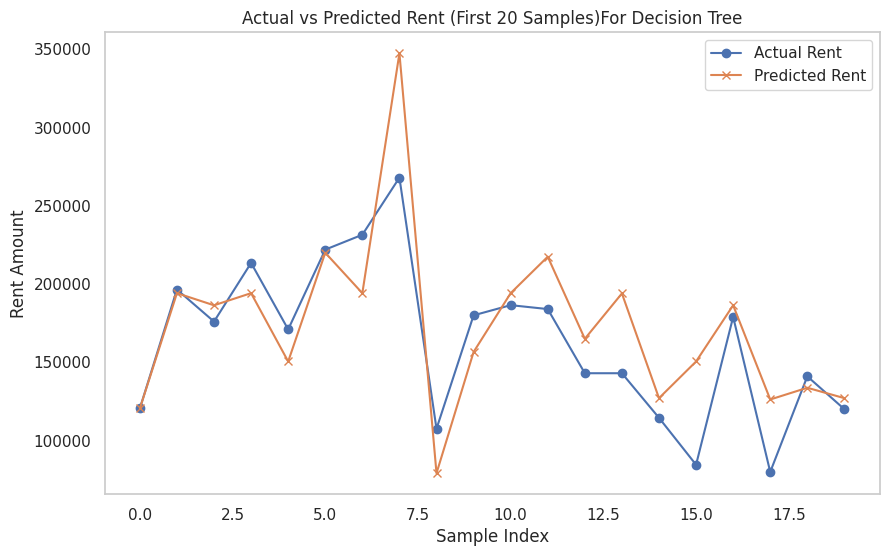

 40%|████      | 6/15 [00:07<00:11,  1.28s/it]

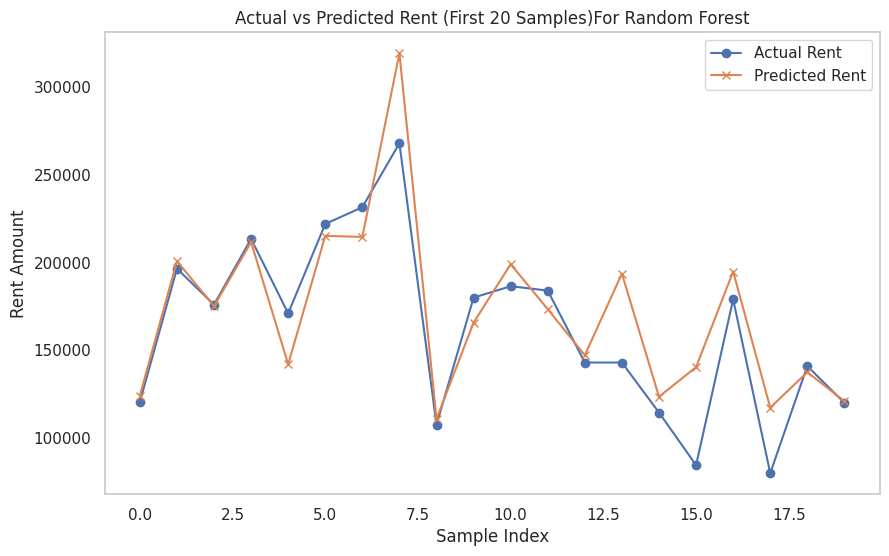

 47%|████▋     | 7/15 [00:10<00:16,  2.05s/it]

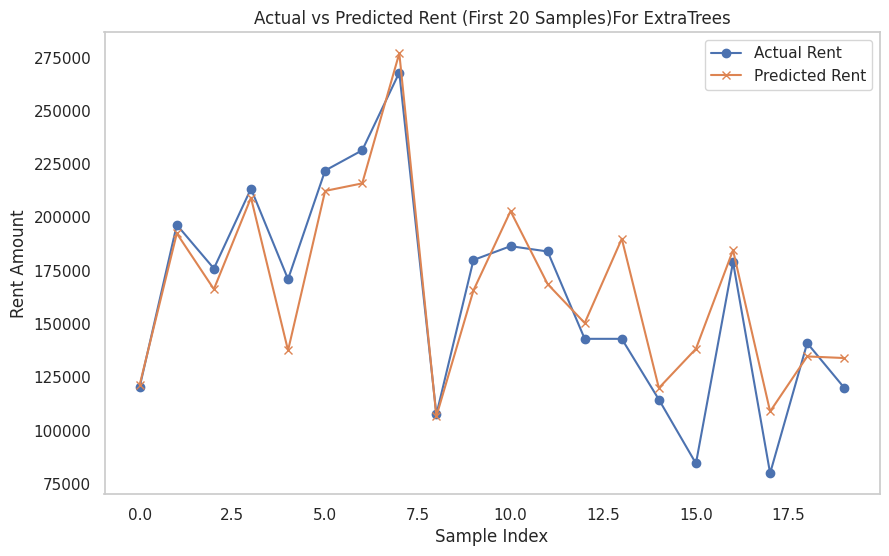

 53%|█████▎    | 8/15 [00:22<00:35,  5.06s/it]

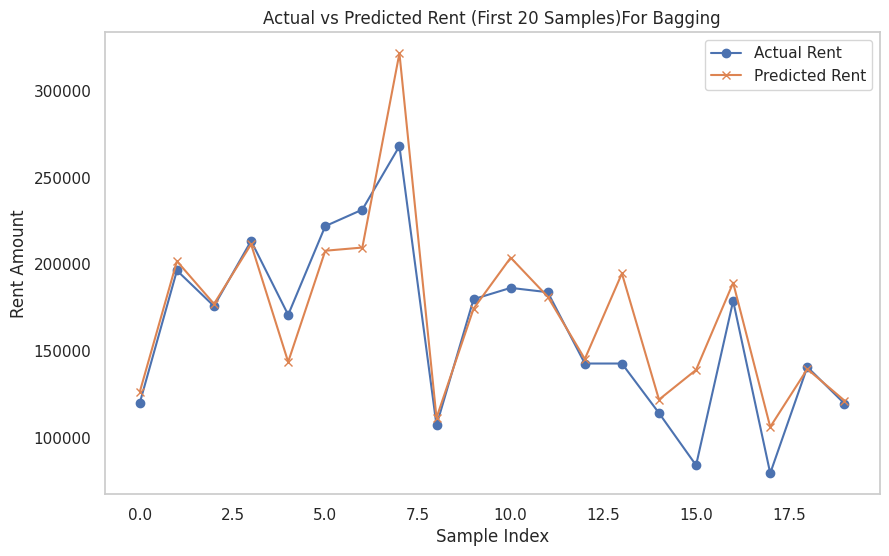

 60%|██████    | 9/15 [00:25<00:27,  4.53s/it]

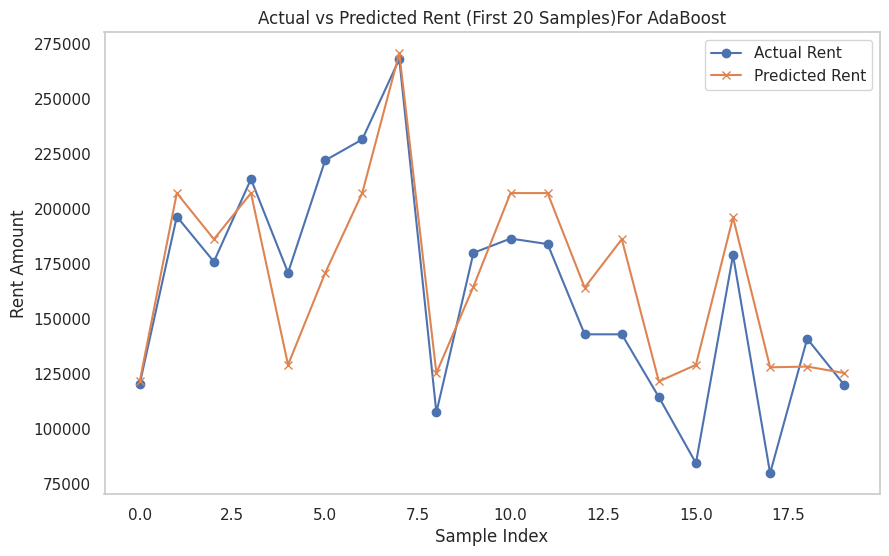

 67%|██████▋   | 10/15 [00:26<00:17,  3.42s/it]

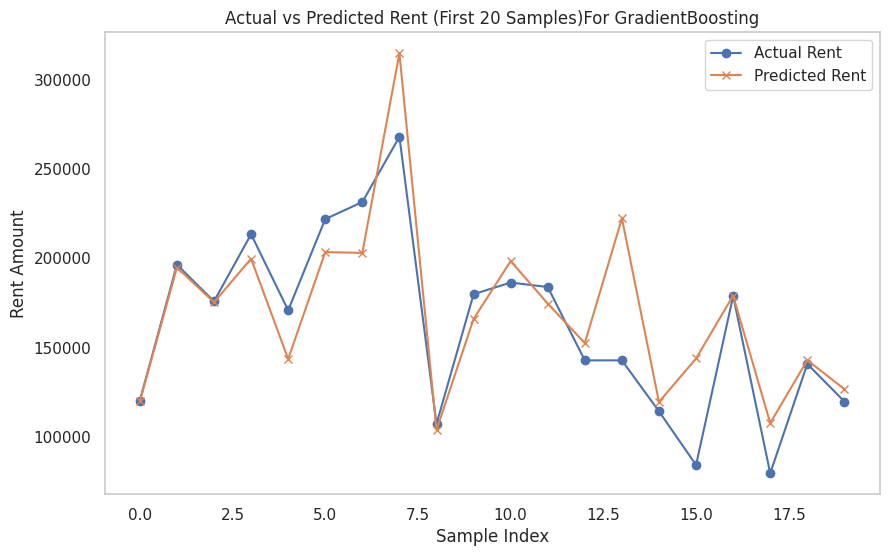

 73%|███████▎  | 11/15 [00:29<00:13,  3.37s/it]

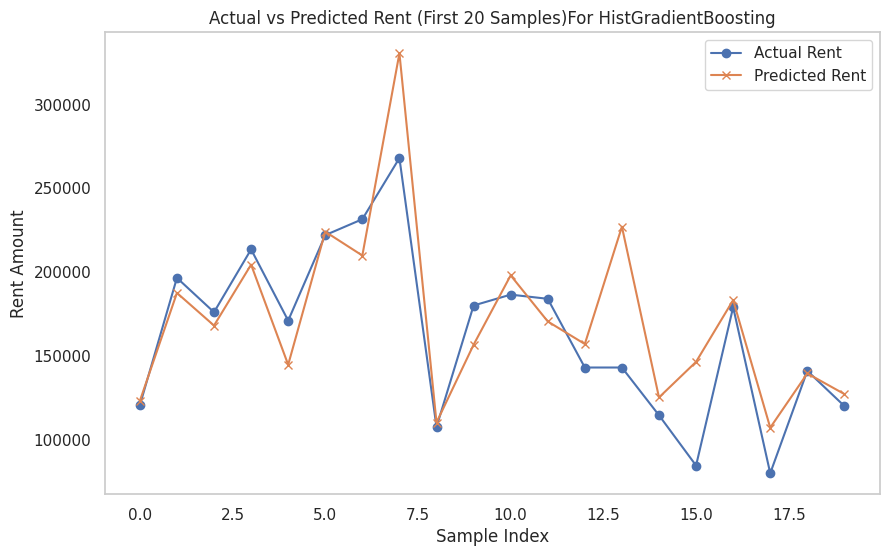

 80%|████████  | 12/15 [00:35<00:12,  4.04s/it]

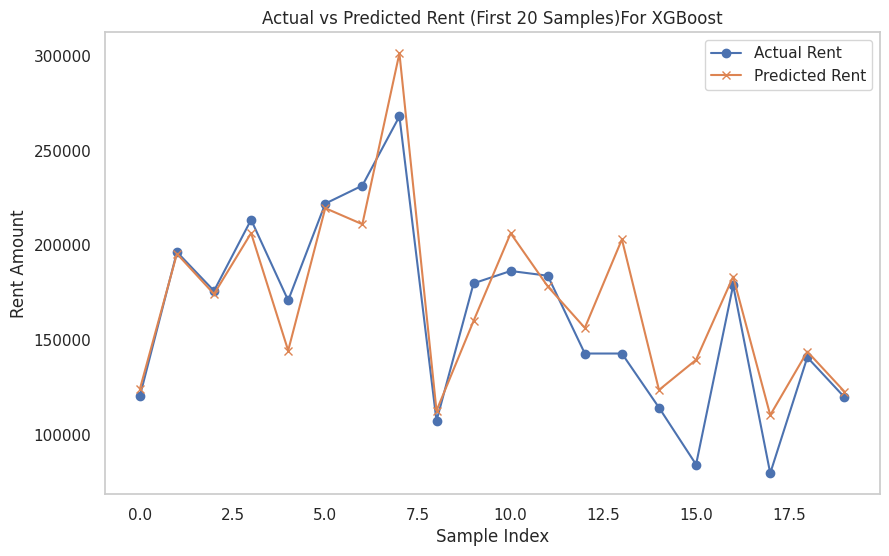

 87%|████████▋ | 13/15 [00:36<00:06,  3.31s/it]

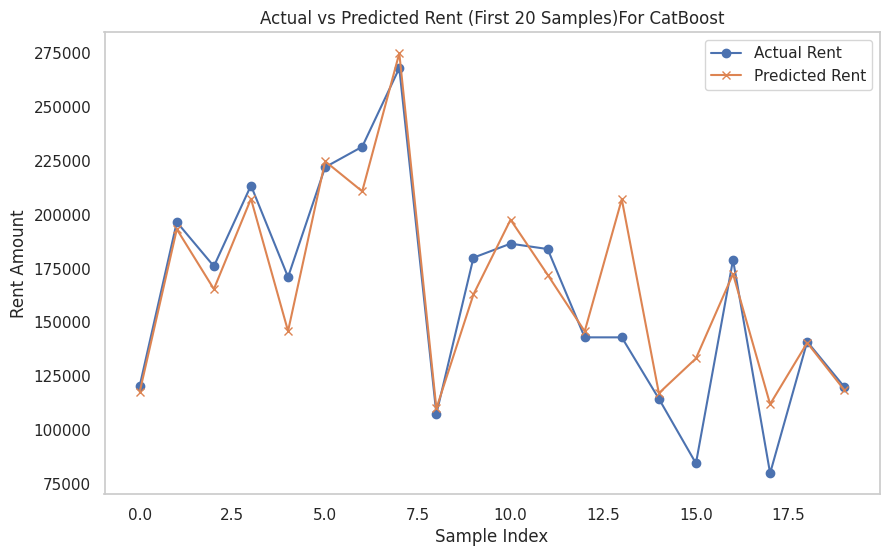

 93%|█████████▎| 14/15 [00:37<00:02,  2.59s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001708 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3257
[LightGBM] [Info] Number of data points in the train set: 1168, number of used features: 185
[LightGBM] [Info] Start training from score 180622.219178


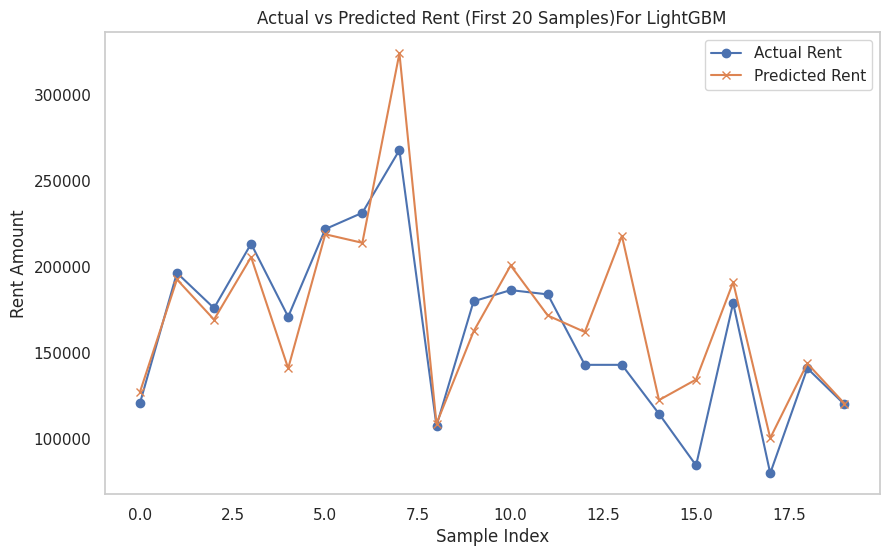

100%|██████████| 15/15 [00:38<00:00,  2.55s/it]


In [100]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(x_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, x_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, x_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(x_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

# **Voting Regression**

In [101]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(x_train, y_train)
model2.fit(x_train, y_train)
model3.fit(x_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, x_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, x_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, x_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, x_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, x_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, x_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# **Stacking Regression**

In [102]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(x_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, x_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, x_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [103]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [104]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
Stacking,6474.696289,16595.925573,1.988465e+08,6.734016e+08,14101.294125,25949.983293,0.968315,0.905674
GradientBoosting,10003.246233,15665.810493,1.837825e+08,6.198662e+08,13556.642129,24897.112245,0.970716,0.903584
LightGBM,5569.409820,16595.925573,1.509771e+08,6.734016e+08,12287.272373,25949.983293,0.975943,0.895257
Simple Voting,5846.521616,16595.925573,8.604711e+07,6.734016e+08,9276.157895,25949.983293,0.986289,0.894855
Voting,5846.521616,16595.925573,8.604711e+07,6.734016e+08,9276.157895,25949.983293,0.986289,0.894855
HistGradientBoosting,5652.301284,16377.995805,1.551245e+08,6.765355e+08,12454.896933,26010.296207,0.975282,0.894770
XGBoost,3574.812500,16095.018555,2.321711e+07,6.854140e+08,4818.414054,26180.411609,0.996301,0.893389
Weighted Voting,5991.554181,16595.925573,8.532977e+07,6.734016e+08,9237.411289,25949.983293,0.986403,0.891733
Random Forest,8160.920439,17370.614989,1.658089e+08,7.228381e+08,12876.680353,26885.648993,0.973579,0.887568
CatBoost,11518.131275,16110.065407,2.395562e+08,7.360976e+08,15477.602693,27131.119004,0.961828,0.885505


<Axes: >

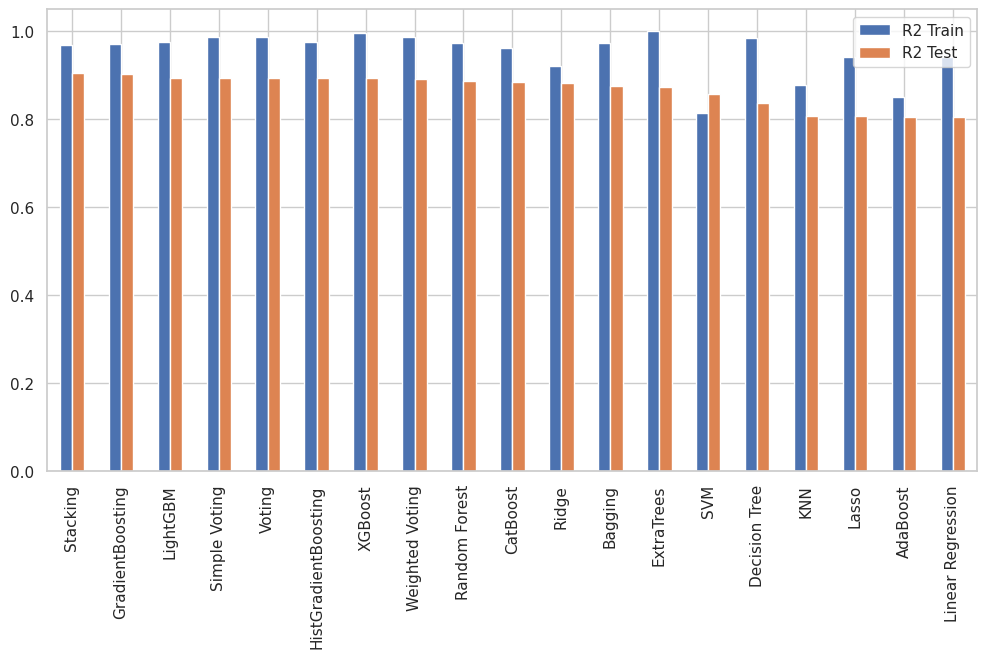

In [105]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

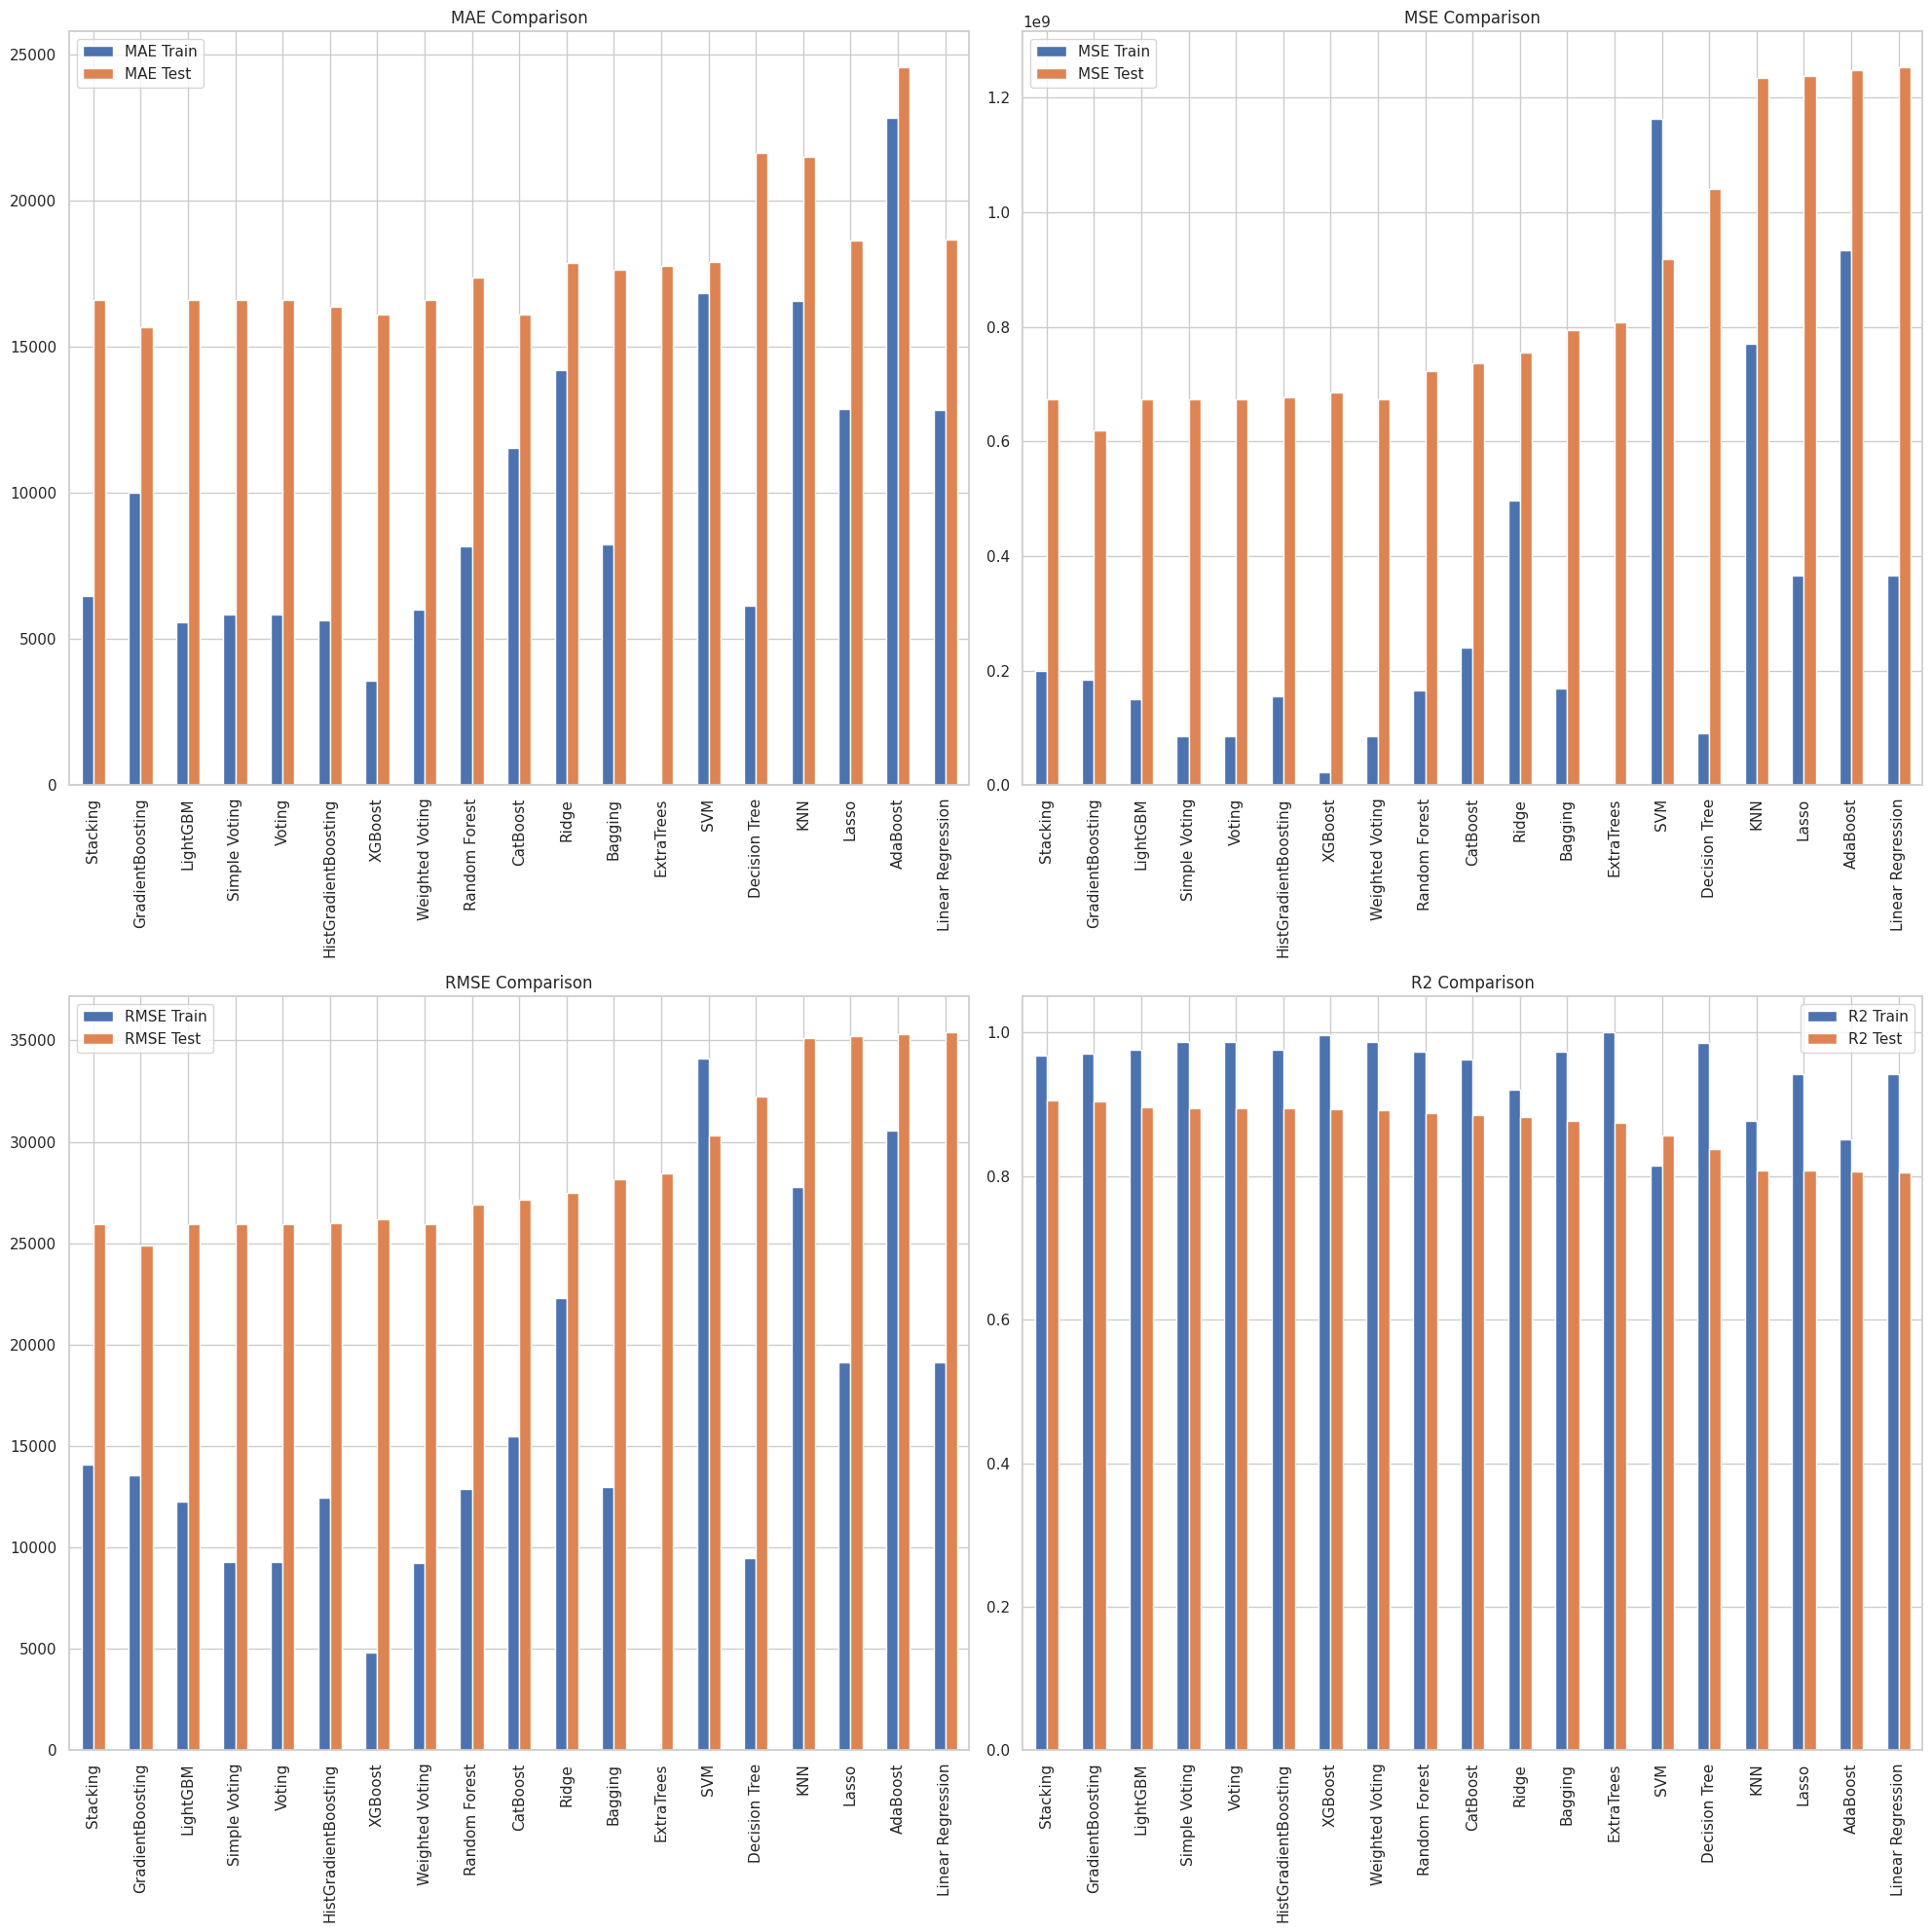

In [106]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()